<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/01_data_understanding_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data Collection / Loading

In [51]:
from pathlib import Path
ZIP_PATH = "/content/drive/MyDrive/DSGP/mit_furniture_subset.zip"   # master copy on Drive
WORK_DIR = Path("/content/mit")                                    # temporary copy on Colab's fast disk

In [52]:
# connect Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
# unzip
import os
assert os.path.exists(ZIP_PATH), f"Zip not found at {ZIP_PATH}. Check the path in the Files sidebar."

!mkdir -p {WORK_DIR}
!unzip -q -o "{ZIP_PATH}" -d {WORK_DIR}

In [54]:
# locate the two folders
img_dir = WORK_DIR / "indoorCVPR_09" / "Images"
ann_dir = WORK_DIR / "indoorCVPR_09annotations" / "Annotations"
print("Images folder exists:", img_dir.exists())
print("Annotations folder exists:", ann_dir.exists())

Images folder exists: True
Annotations folder exists: True


In [55]:
# erify completeness
n_img = len(list(img_dir.rglob("*.jpg")))
n_xml = len(list(ann_dir.rglob("*.xml")))
n_rooms = len([d for d in img_dir.iterdir() if d.is_dir()])

print("Room folders:", n_rooms)
print("Photos:", n_img)
print("Annotation files:", n_xml)

assert n_img > 0 and n_xml > 0, "Nothing loaded"

Room folders: 57
Photos: 1494
Annotation files: 1494


In [56]:
# check photos and labels match
img_names = {p.stem for p in img_dir.rglob("*.jpg")}
xml_names = {p.stem for p in ann_dir.rglob("*.xml")}

print("Photos without a label file:", len(img_names - xml_names))
print("Label files without a photo:", len(xml_names - img_names))

Photos without a label file: 0
Label files without a photo: 0


# 2. Data Understanding

In [57]:
# list the room folders and how many photos each has
for d in sorted(img_dir.iterdir())[:5]:
    print(d.name, "->", len(list(d.glob("*.jpg"))), "photos")

airport_inside -> 5 photos
artstudio -> 27 photos
bakery -> 28 photos
bar -> 34 photos
bathroom -> 56 photos


In [58]:
# read one label file to see how objects are described
sample_xml = next(ann_dir.rglob("*.xml"))
print(sample_xml)
print(sample_xml.read_text()[:1500])

/content/mit/indoorCVPR_09annotations/Annotations/classroom/dark_empty_classroom.xml
<annotation>
<filename>
dark_empty_classroom.jpg
</filename>
<folder>
classroom
</folder>
<source>
<sourceImage>
The MIT-CSAIL database of objects and scenes
</sourceImage>
<sourceAnnotation>
LabelMe Webtool
</sourceAnnotation>
</source>
<object>
<name>
ceiling
</name>
<deleted>
0
</deleted>
<date>
07-Oct-2008 10:43:45
</date>
<id>
1
</id>
<polygon>
<username>
anonymous
</username>
<pt>
<x>
136
</x>
<y>
27
</y>
</pt>
<pt>
<x>
83
</x>
<y>
26
</y>
</pt>
<pt>
<x>
81
</x>
<y>
12
</y>
</pt>
<pt>
<x>
0
</x>
<y>
2
</y>
</pt>
<pt>
<x>
2
</x>
<y>
0
</y>
</pt>
<pt>
<x>
255
</x>
<y>
1
</y>
</pt>
<pt>
<x>
255
</x>
<y>
12
</y>
</pt>
</polygon>
</object>
<object>
<name>
clock
</name>
<deleted>
0
</deleted>
<date>
07-Oct-2008 10:43:45
</date>
<id>
2
</id>
<polygon>
<username>
anonymous
</username>
<pt>
<x>
63
</x>
<y>
43
</y>
</pt>
<pt>
<x>
63
</x>
<y>
38
</y>
</pt>
<pt>
<x>
65
</x>
<y>
35
</y>
</pt>
<pt>
<x>
68
</x>

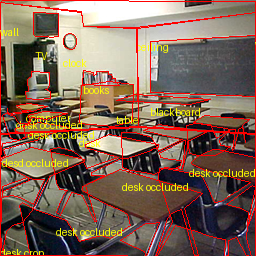

In [59]:
# draw the labelled outlines on one photo to check they match
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw

photo = img_dir / sample_xml.parent.name / (sample_xml.stem + ".jpg")
im = Image.open(photo).convert("RGB")
draw = ImageDraw.Draw(im)
for obj in ET.parse(sample_xml).getroot().findall("object"):
    pts = [(float(p.findtext("x")), float(p.findtext("y"))) for p in obj.findall("polygon/pt")]
    if len(pts) >= 3:
        draw.polygon(pts, outline="red")
        draw.text(pts[0], obj.findtext("name"), fill="yellow")
im

# 3. Exploratory Data Analysis (EDA)

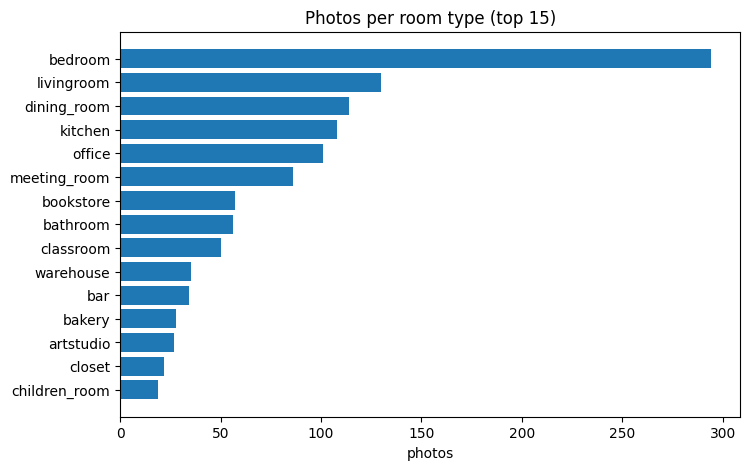

room types: 57 | photos: 1494


In [60]:
# count photos in each room folder and plot the top 15
from collections import Counter
import matplotlib.pyplot as plt

rooms = Counter(p.parent.name for p in img_dir.rglob("*.jpg"))
top = rooms.most_common(15)

plt.figure(figsize=(8, 5))
plt.barh([r for r, _ in top][::-1], [c for _, c in top][::-1])
plt.title("Photos per room type (top 15)")
plt.xlabel("photos")
plt.show()

print("room types:", len(rooms), "| photos:", sum(rooms.values()))

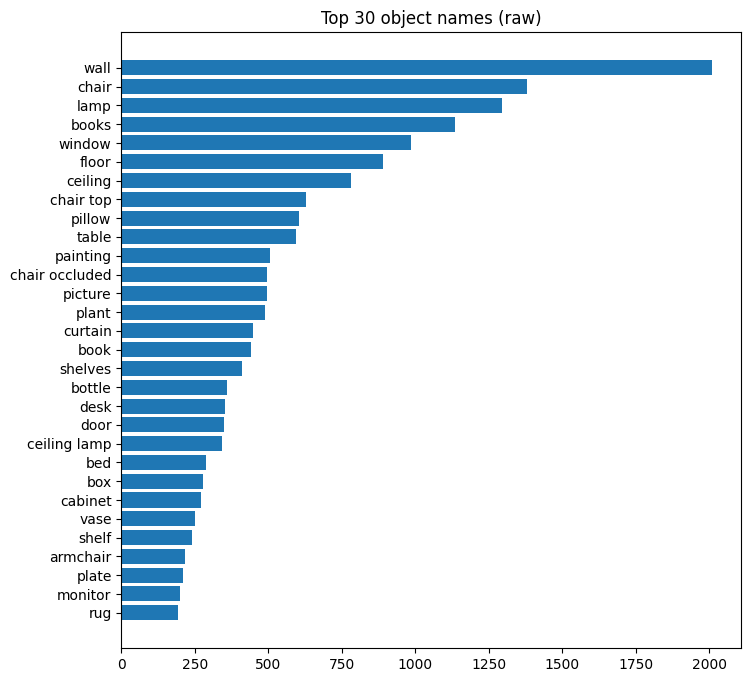

distinct names: 2111 | total labels: 32923


In [61]:
# read every label file and count the raw object names
import xml.etree.ElementTree as ET

names = Counter()
for xml in ann_dir.rglob("*.xml"):
    try:
        root = ET.parse(xml).getroot()
    except ET.ParseError:
        continue
    for obj in root.findall("object"):
        names[(obj.findtext("name") or "").strip().lower()] += 1

top = names.most_common(30)
plt.figure(figsize=(8, 8))
plt.barh([n for n, _ in top][::-1], [c for _, c in top][::-1])
plt.title("Top 30 object names (raw)")
plt.show()

print("distinct names:", len(names), "| total labels:", sum(names.values()))

In [62]:
# count raw object names inside bedroom, livingroom, kitchen and bathroom only
four = ["bedroom", "livingroom", "kitchen", "bathroom"]
per_room = {r: Counter() for r in four}

for xml in ann_dir.rglob("*.xml"):
    room = xml.parent.name
    if room not in per_room:
        continue
    try:
        root = ET.parse(xml).getroot()
    except ET.ParseError:
        continue
    for obj in root.findall("object"):
        per_room[room][(obj.findtext("name") or "").strip().lower()] += 1

for r in four:
    print(f"\n{r.upper()} | photos: {rooms[r]} | labels: {sum(per_room[r].values())}")
    for n, c in per_room[r].most_common(12):
        print(f"{c:5d}  {n}")


BEDROOM | photos: 294 | labels: 4457
  378  wall
  314  pillow
  264  bed
  252  lamp
  201  window
  166  curtain
  150  painting
  149  floor
  125  picture
  111  ceiling
   76  chair
   63  cushion

LIVINGROOM | photos: 130 | labels: 3190
  256  pillow
  118  sofa
  118  lamp
  117  window
  114  plant
  110  wall
  102  painting
  100  small table
   97  chair
   93  books
   91  armchair
   89  vase

KITCHEN | photos: 108 | labels: 3322
  130  cabinet
  130  wall
  125  cabinets
  106  chair
  104  plant
   81  window
   70  floor
   64  pot
   61  sink
   61  counter
   60  cupboard
   57  plate

BATHROOM | photos: 56 | labels: 1089
   75  wall
   51  towel
   39  mirror
   38  bottle
   35  floor
   32  shelf
   29  toilet
   27  sink
   26  window
   24  lamp
   24  cabinet
   23  painting


# 4. Data Quality Assessment

In [63]:
# show the same object appearing under several suffix variants
import re

def base(n):
    return re.sub(r" (occluded|crop|part|top)$", "", n)

for obj in ["chair", "table", "desk", "bed"]:
    variants = {n: c for n, c in names.items() if base(n) == obj}
    print(obj, "->", variants)

chair -> {'chair occluded': 497, 'chair': 1381, 'chair crop': 78, 'chair top': 627, 'chair part': 52}
table -> {'table': 593, 'table crop': 61, 'table occluded': 175, 'table top': 6, 'table part': 2}
desk -> {'desk': 351, 'desk crop': 41, 'desk occluded': 90}
bed -> {'bed': 287, 'bed crop': 43, 'bed occluded': 15, 'bed part': 1}


In [64]:
# counts for names that should probably be one class
synonyms = {
    "painting": ["painting", "picture", "picture frame", "poster"],
    "cabinet":  ["cabinet", "cabinets", "cupboard"],
    "table":    ["table", "small table", "side table", "conference table"],
    "pillow":   ["pillow", "cushion"],
}
for k, v in synonyms.items():
    print(k, {s: names[s] for s in v})

painting {'painting': 506, 'picture': 496, 'picture frame': 94, 'poster': 98}
cabinet {'cabinet': 272, 'cabinets': 166, 'cupboard': 89}
table {'table': 593, 'small table': 151, 'side table': 32, 'conference table': 63}
pillow {'pillow': 605, 'cushion': 145}


In [65]:
# share of each room's labels that are structure, non-furniture or other, for all 4 rooms
four = ["bedroom", "livingroom", "kitchen", "bathroom"]
per_room = {r: Counter() for r in four}

for xml in ann_dir.rglob("*.xml"):
    room = xml.parent.name
    if room not in per_room:
        continue
    try:
        root = ET.parse(xml).getroot()
    except ET.ParseError:
        continue
    for obj in root.findall("object"):
        per_room[room][(obj.findtext("name") or "").strip().lower()] += 1

STRUCT = {"wall", "floor", "ceiling", "window", "door", "column"}
NON_FURN = {"pillow", "cushion", "lamp", "curtain", "painting", "picture", "mirror", "rug",
            "plant", "vase", "books", "book", "bottle", "plate", "bowl", "pot", "towel",
            "faucet", "sink", "stove", "toilet", "washbasin", "glass", "cup", "candle", "jar"}

for r in four:
    total = sum(per_room[r].values())
    s  = sum(c for n, c in per_room[r].items() if base(n) in STRUCT)
    nf = sum(c for n, c in per_room[r].items() if base(n) in NON_FURN)
    print(f"{r:11} structure {s/total:5.0%} | non-furniture {nf/total:5.0%} | other {1-(s+nf)/total:5.0%}")

bedroom     structure   20% | non-furniture   31% | other   49%
livingroom  structure   11% | non-furniture   36% | other   52%
kitchen     structure   11% | non-furniture   23% | other   66%
bathroom    structure   16% | non-furniture   34% | other   51%


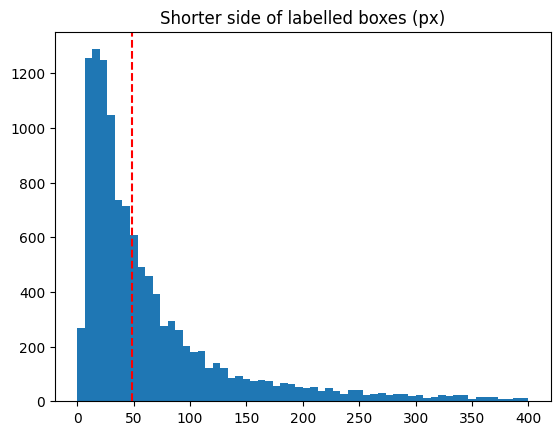

55% of boxes are under 48px


In [66]:
# measure the shorter side of every labelled outline in the four target rooms
MIN_SIDE = 48
sizes = []
for xml in ann_dir.rglob("*.xml"):
    if xml.parent.name not in four:
        continue
    try:
        root = ET.parse(xml).getroot()
    except ET.ParseError:
        continue
    for o in root.findall("object"):
        pts = [(float(p.findtext("x")), float(p.findtext("y"))) for p in o.findall("polygon/pt")]
        if len(pts) >= 3:
            xs, ys = zip(*pts)
            sizes.append(min(max(xs) - min(xs), max(ys) - min(ys)))

plt.hist(sizes, bins=60, range=(0, 400))
plt.axvline(MIN_SIDE, color="red", ls="--")
plt.title("Shorter side of labelled boxes (px)")
plt.show()
print(f"{sum(s < MIN_SIDE for s in sizes) / len(sizes):.0%} of boxes are under {MIN_SIDE}px")

In [67]:
# check which wanted furniture classes exist in the data at all
base_names = Counter()
for n, c in names.items():
    base_names[base(n)] += c

wanted = {
    "wardrobe": ["wardrobe", "closet"], "dresser": ["dresser", "drawers", "drawer"],
    "nightstand": ["night table", "nightstand"], "bookshelf": ["shelf", "shelves", "bookcase"],
    "coffee_table": ["coffee table"], "side_table": ["small table", "side table"],
    "ottoman": ["ottoman"], "bar_stool": ["stool"], "tv_stand": ["tv stand"],
    "console_table": ["console table"], "sideboard": ["sideboard"], "kitchen_island": ["kitchen island"],
}
for cls, srcs in wanted.items():
    print(f"{cls:15} {sum(base_names[s] for s in srcs):5}")

wardrobe          130
dresser           149
nightstand         71
bookshelf         830
coffee_table       21
side_table        186
ottoman            45
bar_stool         103
tv_stand           11
console_table       2
sideboard           4
kitchen_island      2


In [68]:
# share of photos that belong to our four rooms
n4 = sum(rooms[r] for r in four)
print(f"{n4} of {sum(rooms.values())} photos ({n4 / sum(rooms.values()):.0%}) are in our 4 rooms")

588 of 1494 photos (39%) are in our 4 rooms


| # | Problem | Evidence | Fix (Step) |
|---|---------|----------|------------|
| A | Same object, many spellings | chair vs chair top / occluded / crop | Normalise names (5) |
| B | Synonyms split one class | painting / picture / poster | Merge classes (5) |
| C | Many labels are not furniture | 30% non-furniture, 20% structure | Remove (5) |
| D | Many tiny boxes | 55% under 48px | Filter (5) |
| E | Most photos are other rooms | 39% in our 4 rooms | Keep 4 rooms (5) |
| F | Missing / rare classes | tv_stand = 0, sideboard = 0 ... | Add data (6) |

# 5. Data Preprocessing

In [69]:
# normalise label names and group them into our furniture classes
def norm(name):
    n = (name or "").strip().lower()
    for suf in (" occluded", " crop", " part", " top"):
        n = n.replace(suf, "")
    return n.strip()

LABEL_MAP = {
    "chair": "chair", "swivel chair": "chair",
    "armchair": "armchair", "sofa": "sofa", "couch": "sofa",
    "bed": "bed", "desk": "desk", "desks": "desk",
    "table": "table", "conference table": "table",
    "coffee table": "coffee_table", "small table": "side_table", "side table": "side_table",
    "wardrobe": "wardrobe", "closet": "wardrobe",
    "dresser": "dresser", "drawer": "dresser", "drawers": "dresser",
    "night table": "nightstand", "nightstand": "nightstand",
    "shelf": "bookshelf", "shelves": "bookshelf", "bookcase": "bookshelf",
    "ottoman": "stool_ottoman", "stool": "stool_ottoman",
    "cabinet": "storage_cabinet", "cabinets": "storage_cabinet", "cupboard": "storage_cabinet",
    "sideboard": "storage_cabinet",
}

In [70]:
# collect one record per furniture object in the four target rooms
records = []
for xml in sorted(ann_dir.rglob("*.xml")):
    room = xml.parent.name
    if room not in four:
        continue
    photo = img_dir / room / (xml.stem + ".jpg")
    if not photo.exists():
        continue
    try:
        root = ET.parse(xml).getroot()
    except ET.ParseError:
        continue
    for obj in root.findall("object"):
        cls = LABEL_MAP.get(norm(obj.findtext("name")))
        if cls is None or (cls == "storage_cabinet" and room == "kitchen"):
            continue
        pts = [(float(p.findtext("x")), float(p.findtext("y"))) for p in obj.findall("polygon/pt")]
        if len(pts) >= 3:
            xs, ys = zip(*pts)
            records.append({"photo": str(photo), "room": room, "cls": cls,
                            "x0": min(xs), "y0": min(ys), "x1": max(xs), "y1": max(ys)})

df = pd.DataFrame(records)
print(len(df), "furniture objects in", df["photo"].nunique(), "photos")

2028 furniture objects in 588 photos


In [71]:
# drop boxes whose shorter side is under MIN_SIDE pixels
df["w"], df["h"] = df.x1 - df.x0, df.y1 - df.y0
before = len(df)
df = df[df[["w", "h"]].min(axis=1) >= MIN_SIDE].copy()
print(f"removed {before - len(df)} tiny boxes, {len(df)} left")

removed 632 tiny boxes, 1396 left


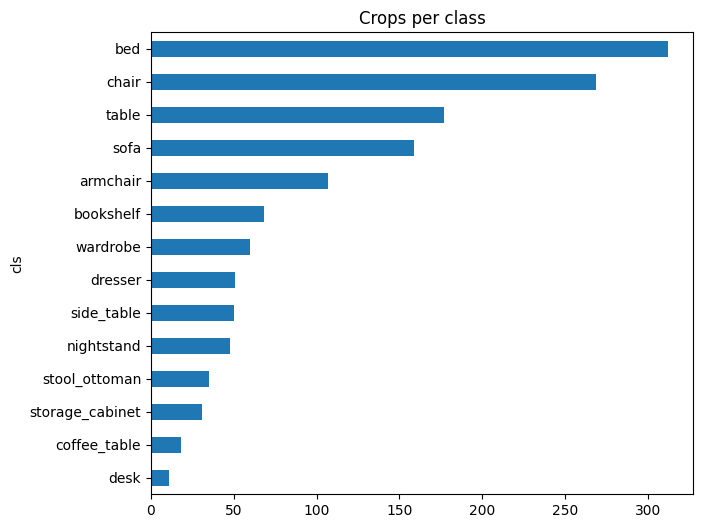

In [72]:
# keep at most MAX_PER_CLASS crops per class so chair/table don't dominate
MAX_PER_CLASS = 600
df = df.sample(frac=1, random_state=42).groupby("cls").head(MAX_PER_CLASS).reset_index(drop=True)

df["cls"].value_counts().sort_values().plot(kind="barh", figsize=(7, 6), title="Crops per class")
plt.show()

In [73]:
# save each box as its own image in furniture_v1/<class>/ and write a manifest
import shutil
shutil.rmtree("/content/furniture_v1", ignore_errors=True)
from PIL import Image

OUT = Path("/content/furniture_v1")
paths = []
for i, r in enumerate(df.itertuples()):
    d = OUT / r.cls
    d.mkdir(parents=True, exist_ok=True)
    p = d / f"{Path(r.photo).stem}_{i}.jpg"
    Image.open(r.photo).convert("RGB").crop((int(r.x0), int(r.y0), int(r.x1), int(r.y1))).save(p)
    paths.append(str(p))

df["crop_path"] = paths
df.to_csv("/content/drive/MyDrive/DSGP/furniture_v1_manifest.csv", index=False)
print(len(df), "crops saved")

1396 crops saved


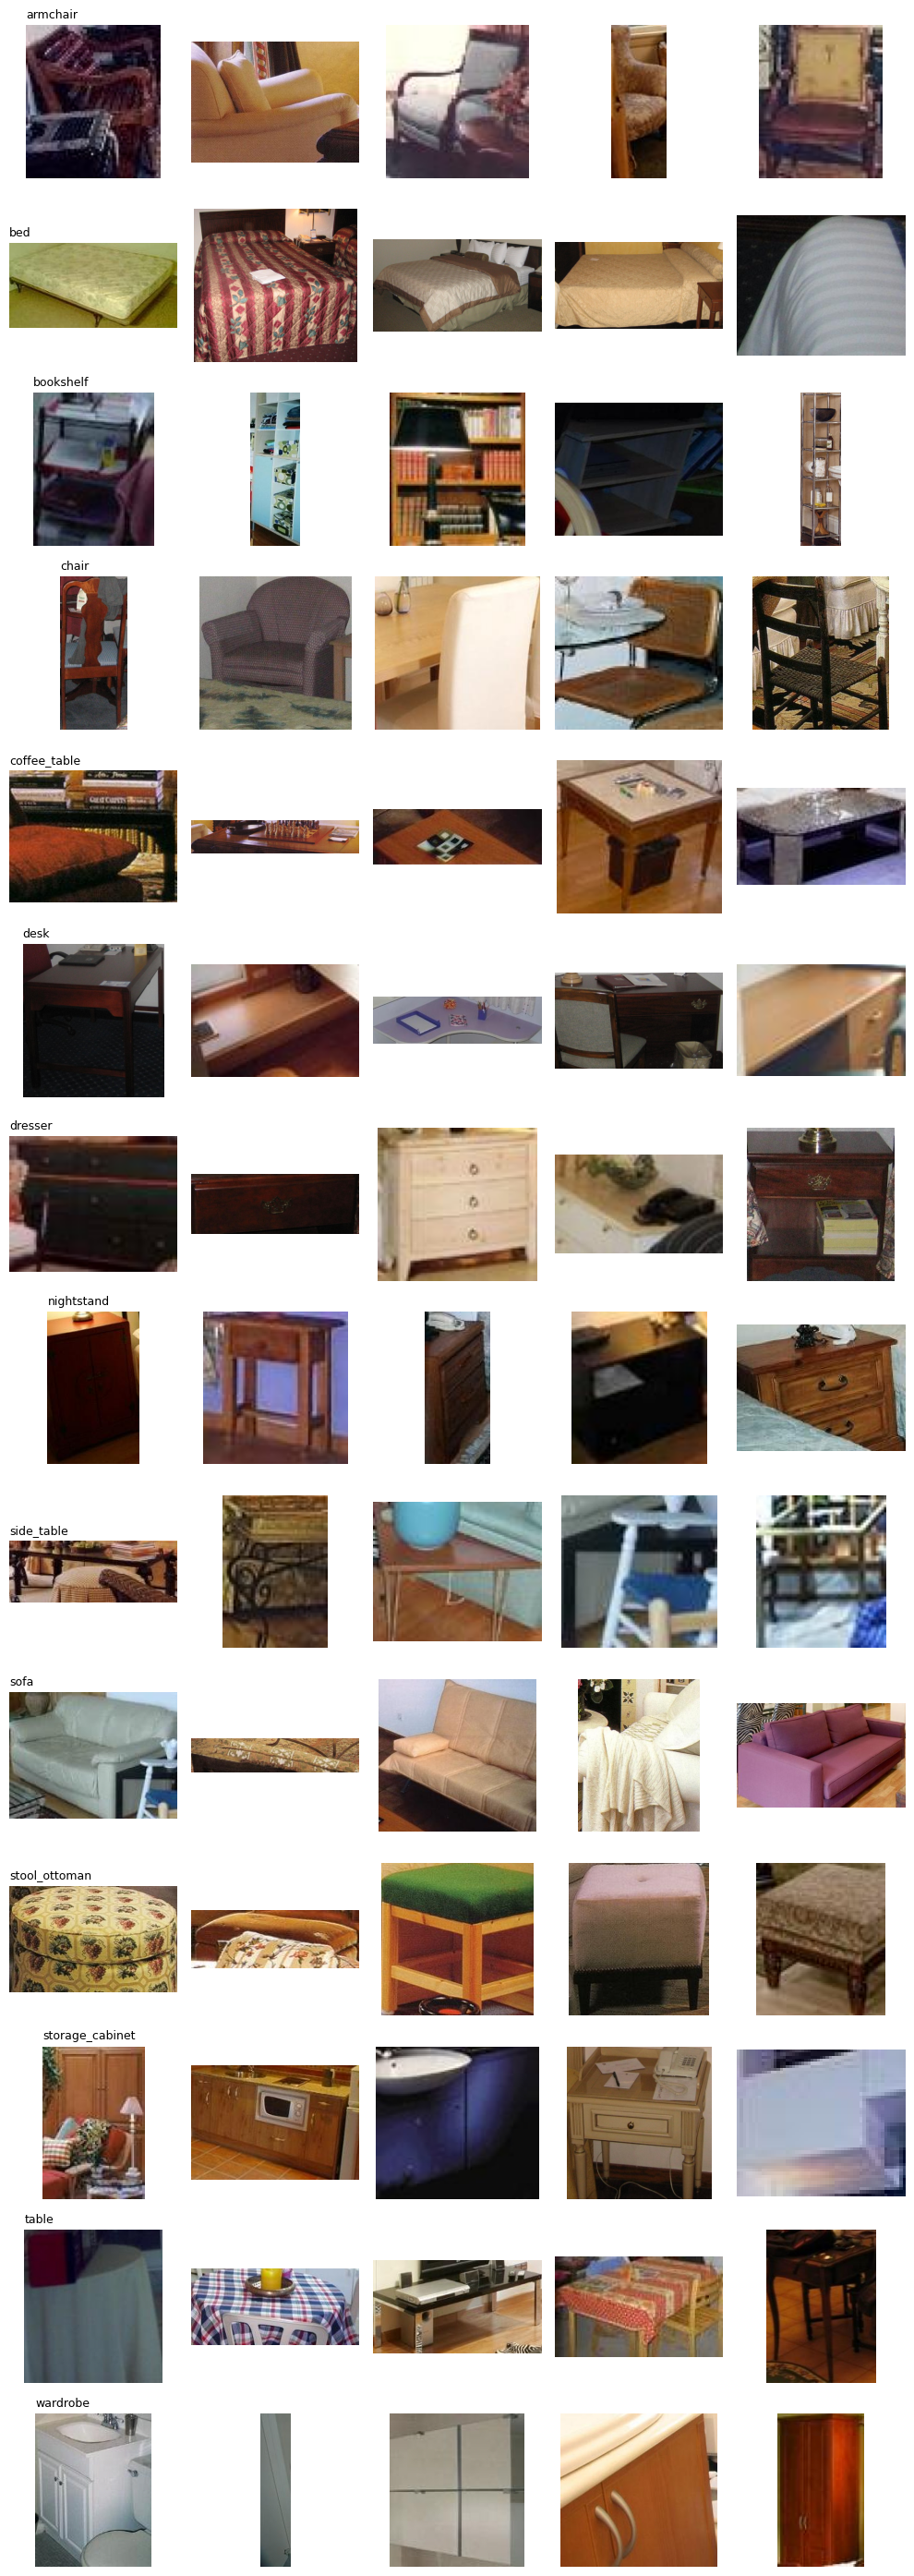

In [74]:
# show 5 random crops per class to confirm they look right
classes = sorted(df["cls"].unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for row, c in enumerate(classes):
    sample = df[df.cls == c].sample(min(5, (df.cls == c).sum()), random_state=1)
    for col in range(5):
        ax = axes[row][col]
        ax.axis("off")
        if col < len(sample):
            ax.imshow(Image.open(sample.iloc[col].crop_path))
        if col == 0:
            ax.set_title(c, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

In [75]:
# save a standard manifest, the label map and a zip of the crops to Drive
import json
DRIVE = "/content/drive/MyDrive/DSGP"

v1 = pd.DataFrame({
    "path": df["crop_path"], "cls": df["cls"], "source": "mit_indoor",
    "group_id": df["photo"].map(lambda p: "mit_" + Path(p).stem),
    "room_crop": True, "width": df["w"].astype(int), "height": df["h"].astype(int),
})
v1.to_csv(f"{DRIVE}/furniture_v1_manifest.csv", index=False)
json.dump(LABEL_MAP, open(f"{DRIVE}/mit_label_map.json", "w"), indent=2)
!cd /content && zip -q -r {DRIVE}/furniture_v1.zip furniture_v1
print(v1["cls"].value_counts())

cls
bed                312
chair              269
table              177
sofa               159
armchair           107
bookshelf           68
wardrobe            60
dresser             51
side_table          50
nightstand          48
stool_ottoman       35
storage_cabinet     31
coffee_table        18
desk                11
Name: count, dtype: int64
